# Overview

This project compares multiple machine learning models to predict car prices based on features like manufacturer, model, fuel type, and age.

# 1. Import Libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer

from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

import xgboost as xgb
import joblib

# 2. Load Data

In [2]:
data = pd.read_csv('/kaggle/input/datasets/youssefmahdyabosaleh/car-sales-data/car_sales_data.csv')

# 3. Data Preprocessing


In [3]:

# Feature Engineering
data['age'] = 2025 - data['Year of manufacture']

# Drop unnecessary column
data = data.drop(['Year of manufacture'], axis=1)

# Handle missing values (simple)
data = data.dropna()

# Separate features
X = data.drop('Price', axis=1)
y = data['Price']

# Identify categorical & numerical columns
categorical_cols = ['Manufacturer', 'Fuel type', 'Model']
numerical_cols = [col for col in X.columns if col not in categorical_cols]




#  4. Preprocessing Pipeline


In [4]:
from sklearn.preprocessing import OneHotEncoder

preprocessor = ColumnTransformer([
    ('num', StandardScaler(), numerical_cols),
    ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_cols)
])

# 5. Train-Test Split

In [5]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 6. Models Used
📈 Linear Models

Linear Regression

Ridge

Lasso

🌳 Tree Models

Decision Tree

Random Forest

🚀 Boosting

Gradient Boosting

XGBoost

In [6]:
'''models={
    'Linear':LinearRegression(),
    'Ridge':Ridge(alpha=1.0),
    'Lasso':Lasso(alpha=0.01),
    'Decision Tree':DecisionTreeRegressor(max_depth=10, random_state=42),
    'Random Forest':RandomForestRegressor(n_estimators=200, random_state=42),
    'Gradient Boosting':GradientBoostingRegressor(n_estimators=200, random_state=42),
    'xgboost':xgb.XGBRegressor(n_estimators=200, learning_rate=0.1, random_state=42)
}
'''
models = {
    "Linear Regression": LinearRegression(),
    "Ridge": Ridge(),
    "Lasso": Lasso(),
    "Decision Tree": DecisionTreeRegressor(),
    "Random Forest": RandomForestRegressor(),
    "Gradient Boosting": GradientBoostingRegressor(),
    "XGBoost": xgb.XGBRegressor()
}



# 7. Model Training & Evaluation

In [7]:
results = []

for name, model in models.items():
    pipe = Pipeline([
        ('preprocessor', preprocessor),
        ('model', model)
    ])
    
    pipe.fit(X_train, y_train)
    y_pred = pipe.predict(X_test)
    
    mae = mean_absolute_error(y_test, y_pred)
    r2 = r2_score(y_test, y_pred)
    mse = mean_squared_error(y_test, y_pred)

    # Cross Validation
    cv_scores = cross_val_score(pipe, X, y, cv=5, scoring='r2')
    
    results.append({
        "Model": name,
        "MAE": mae,
        "R2": r2,
        "MSE": mse,
        "CV_R2_Mean": np.mean(cv_scores)
    })

# Show results
results_df = pd.DataFrame(results).sort_values(by="R2", ascending=False)
print(results_df)

               Model          MAE        R2           MSE  CV_R2_Mean
6            XGBoost   321.149536  0.998974  2.783594e+05    0.998930
4      Random Forest   290.230654  0.998536  3.972520e+05    0.998471
3      Decision Tree   434.965400  0.996680  9.008712e+05    0.996441
5  Gradient Boosting  1037.393297  0.989926  2.733896e+06    0.989516
0  Linear Regression  5786.312537  0.710195  7.864602e+07    0.714646
1              Ridge  5786.139619  0.710192  7.864678e+07    0.714647
2              Lasso  5785.537775  0.710177  7.865070e+07    0.714644


#  8. Visualization



Best Model: XGBoost


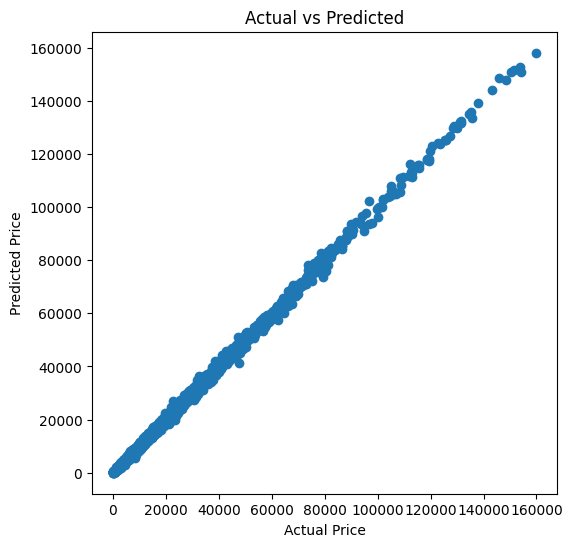

In [8]:
best_model_name = results_df.iloc[0]["Model"]
print(f"\nBest Model: {best_model_name}")

best_model = models[best_model_name]

best_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('model', best_model)
])

best_pipeline.fit(X_train, y_train)
y_pred = best_pipeline.predict(X_test)

plt.figure(figsize=(6,6))
plt.scatter(y_test, y_pred)
plt.xlabel("Actual Price")
plt.ylabel("Predicted Price")
plt.title("Actual vs Predicted")
plt.show()

#  9. Hyperparameter Tuning (Random Forest Example)


In [9]:
param_grid = {
    'model__n_estimators': [100, 200],
    'model__max_depth': [None, 10, 20]
}

rf_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('model', RandomForestRegressor(random_state=42))
])

grid = GridSearchCV(rf_pipeline, param_grid, cv=3, scoring='r2', n_jobs=-1)
grid.fit(X_train, y_train)

print("\nBest Parameters:", grid.best_params_)



Best Parameters: {'model__max_depth': None, 'model__n_estimators': 200}


#  10. Save Model


In [10]:
joblib.dump(grid.best_estimator_, "best_car_price_model.pkl")


['best_car_price_model.pkl']

#  11. Load Model Example


In [11]:
loaded_model = joblib.load("best_car_price_model.pkl")

sample = X_test.iloc[0:1]
prediction = loaded_model.predict(sample)

print("\nSample Prediction:", prediction)


Sample Prediction: [67823.715]
